# AI-Based Industrial Maintenance — Model Training & Comparison

**Goal:** Download/load the UCI AI4I 2020 Predictive Maintenance dataset, inspect and prepare it, compare multiple classifiers fairly, select a model using validation metrics, evaluate the selected model on a held-out test set, and export a reusable `.pkl` model.

> Recommended runtime: Google Colab or Kaggle Notebook, Python 3.10+.
>
> Important: this dataset is simulated. The classifier predicts the dataset's `Machine failure` label; it does not by itself estimate Remaining Useful Life (RUL), real energy consumption, or real-world causal effects.

## 1. Install dependencies

Run this cell once in the notebook environment.

In [1]:
%pip -q install ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib

## 2. Download the dataset from UCI

This uses the official UCI dataset loader. If that download is unavailable in your environment, use the fallback CSV URL cell below.

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

RANDOM_STATE = 42
TARGET = "Machine failure"

try:
    dataset = fetch_ucirepo(id=601)
    X_raw = dataset.data.features.copy()
    y_raw = dataset.data.targets.copy()

    # The official UCI loader usually returns the target separately.
    print("Downloaded AI4I 2020 dataset from UCI.")
    print("Feature shape:", X_raw.shape)
    print("Target columns:", list(y_raw.columns))
except Exception as exc:
    print("UCI loader failed:", repr(exc))
    print("Use the fallback CSV cell in the next section if needed.")
    raise

Downloaded AI4I 2020 dataset from UCI.
Feature shape: (10000, 6)
Target columns: ['Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


### Fallback option (only if the official loader fails)

Download the CSV from the [official UCI dataset page](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset), upload it to Colab/Kaggle, then set `CSV_PATH` below. Run this cell **instead of** the previous download cell.

In [ ]:
# Uncomment and edit only if the UCI loader above failed.
#
# from google.colab import files
# uploaded = files.upload()  # choose ai4i2020.csv
# CSV_PATH = next(iter(uploaded))
#
# # For Kaggle, CSV_PATH may look like:
# # CSV_PATH = "/kaggle/input/your-dataset-folder/ai4i2020.csv"
#
# df = pd.read_csv(CSV_PATH)
# target_candidates = [c for c in df.columns if c.strip().lower() == "machine failure"]
# if not target_candidates:
#     raise ValueError(f"Could not find 'Machine failure'. Columns: {df.columns.tolist()}")
# target_col = target_candidates[0]
# y_raw = df[[target_col]].rename(columns={target_col: TARGET})
# X_raw = df.drop(columns=[target_col])

## 3. Combine target and features, inspect the data

We explicitly exclude the failure-mode columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) because they are labels describing failure types and can leak the answer. Identifiers (`UDI`, `Product ID`) are also excluded from model inputs.

In [3]:
# Normalize target to a one-dimensional integer Series.
if isinstance(y_raw, pd.DataFrame):
    target_matches = [c for c in y_raw.columns if c.strip().lower() == TARGET.lower()]
    if target_matches:
        y = y_raw[target_matches[0]].copy()
    elif y_raw.shape[1] == 1:
        y = y_raw.iloc[:, 0].copy()
    else:
        raise ValueError(f"Unexpected target columns: {y_raw.columns.tolist()}")
else:
    y = pd.Series(y_raw, name=TARGET)

y = pd.to_numeric(y, errors="raise").astype(int).reset_index(drop=True)
X_all = X_raw.reset_index(drop=True).copy()

print("Rows, columns:", X_all.shape)
print("\nFeature columns:")
print(X_all.columns.tolist())
print("\nTarget distribution:")
print(y.value_counts().sort_index().rename(index={0: "No failure (0)", 1: "Failure (1)"}))
print("\nTarget percentages:")
print((y.value_counts(normalize=True).sort_index() * 100).round(2))
print("\nMissing values per column:")
display(X_all.isna().sum().to_frame("missing_count"))
display(X_all.head())

if set(y.unique()) - {0, 1}:
    raise ValueError(f"Expected binary target 0/1; got {sorted(y.unique())}")

# Remove identifier columns and failure-mode leakage columns if present.
leakage_or_id_columns = [
    c for c in X_all.columns
    if c.strip().lower() in {
        "udi", "product id", "twf", "hdf", "pwf", "osf", "rnf"
    }
]
X = X_all.drop(columns=leakage_or_id_columns, errors="ignore").copy()

print("\nExcluded columns:", leakage_or_id_columns)
print("Model input columns:", X.columns.tolist())

Rows, columns: (10000, 6)

Feature columns:
['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']

Target distribution:
Machine failure
No failure (0)    9661
Failure (1)        339
Name: count, dtype: int64

Target percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Missing values per column:


,missing_count
Type,0
Air temperature,0
Process temperature,0
Rotational speed,0
Torque,0
Tool wear,0


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9



Excluded columns: []
Model input columns: ['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']


## 4. Quick visual inspection

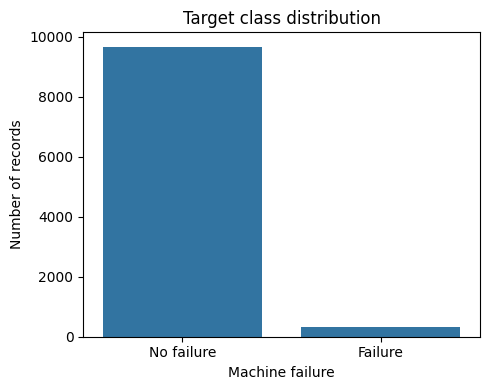

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature,10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature,10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed,10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque,10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear,10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0


In [4]:
plt.figure(figsize=(5, 4))
sns.countplot(x=y.map({0: "No failure", 1: "Failure"}))
plt.title("Target class distribution")
plt.xlabel("Machine failure")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

display(X.describe(include="all").T)

## 5. Split into train, validation, and test sets

- **Training set:** fits models.
- **Validation set:** compares models and selects a candidate.
- **Test set:** used once at the end for an unbiased final evaluation.

We use stratification because failures are uncommon. No resampling is performed before splitting, which prevents data leakage.

In [5]:
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.25, random_state=RANDOM_STATE, stratify=y_train_full
)

print(f"Train:      {len(X_train):,} rows ({len(X_train)/len(X):.0%})")
print(f"Validation: {len(X_val):,} rows ({len(X_val)/len(X):.0%})")
print(f"Test:       {len(X_test):,} rows ({len(X_test)/len(X):.0%})")
print("\nFailure rate by split:")
for name, labels in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"{name}: {labels.mean():.3%} failures")

Train:      6,000 rows (60%)
Validation: 2,000 rows (20%)
Test:       2,000 rows (20%)

Failure rate by split:
Train: 3.383% failures
Validation: 3.400% failures
Test: 3.400% failures


## 6. Build preprocessing and candidate models

The pipeline handles missing values and categorical `Type` values consistently. We compare:
- Dummy majority-class baseline
- Logistic Regression (class-weighted)
- Decision Tree (class-weighted)
- Random Forest (class-weighted)
- Extra Trees (class-weighted)
- Histogram Gradient Boosting (with one-hot encoded inputs)

Model selection prioritizes **validation average precision (PR-AUC)**, which is informative for rare positive classes. We also report failure-class precision, recall and F1 at the default 0.5 threshold. The best metric for a deployment may differ depending on the relative cost of missed failures versus false alarms.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    classification_report
)

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))
    numeric_pipe = Pipeline(numeric_steps)

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_features),
        ("categorical", categorical_pipe, categorical_features)
    ], remainder="drop")

candidates = {
    "Dummy baseline": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("preprocess", make_preprocessor(scale_numeric=True)),
        ("model", LogisticRegression(
            class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE
        ))
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", DecisionTreeClassifier(
            class_weight="balanced", min_samples_leaf=5, random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=400, class_weight="balanced",
            min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", ExtraTreesClassifier(
            n_estimators=400, class_weight="balanced",
            min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("preprocess", make_preprocessor()),
        ("model", HistGradientBoostingClassifier(
            max_iter=150, learning_rate=0.08, max_leaf_nodes=15,
            l2_regularization=1.0, random_state=RANDOM_STATE
        ))
    ])
}

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Models to compare:", list(candidates))

Numeric features: ['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear']
Categorical features: ['Type']
Models to compare: ['Dummy baseline', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees', 'Hist Gradient Boosting']


## 7. Train candidates and compare validation performance

This cell trains each model on the training set and evaluates on the validation set. It does not inspect the test set for model selection.

Training: Dummy baseline
Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: Hist Gradient Boosting


,model,precision_failure,recall_failure,f1_failure,accuracy,average_precision,roc_auc
0,Hist Gradient Boosting,0.745,0.559,0.639,0.979,0.712,0.973
1,Random Forest,0.755,0.544,0.632,0.979,0.703,0.965
2,Extra Trees,0.543,0.735,0.625,0.970,0.665,0.963
3,Decision Tree,0.371,0.721,0.490,0.949,0.443,0.847
4,Logistic Regression,0.142,0.824,0.243,0.826,0.368,0.879
5,Dummy baseline,0.000,0.000,0.000,0.966,0.034,0.500


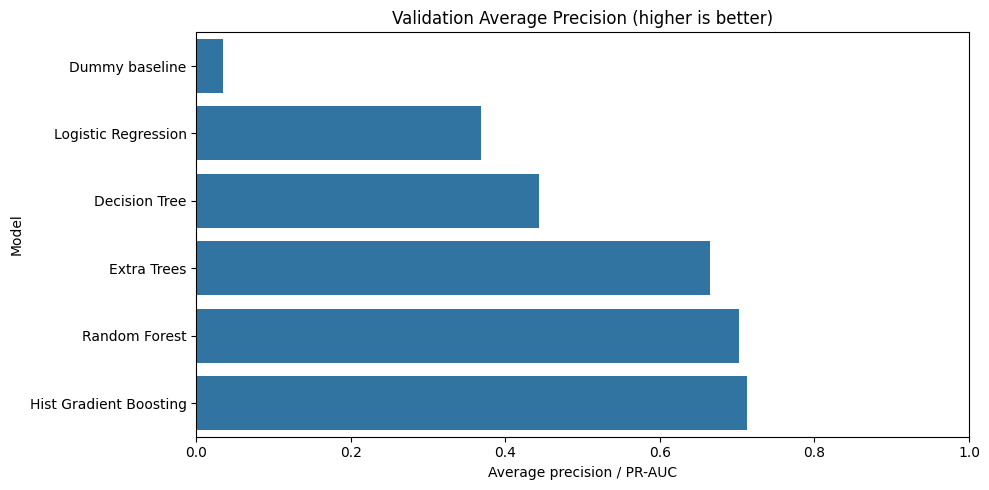

In [7]:
results = []
fitted_candidates = {}

for name, estimator in candidates.items():
    print(f"Training: {name}")
    estimator.fit(X_train, y_train)
    fitted_candidates[name] = estimator

    val_pred = estimator.predict(X_val)
    row = {
        "model": name,
        "precision_failure": precision_score(y_val, val_pred, zero_division=0),
        "recall_failure": recall_score(y_val, val_pred, zero_division=0),
        "f1_failure": f1_score(y_val, val_pred, zero_division=0),
        "accuracy": accuracy_score(y_val, val_pred),
    }

    if hasattr(estimator, "predict_proba"):
        val_prob = estimator.predict_proba(X_val)[:, 1]
        row["average_precision"] = average_precision_score(y_val, val_prob)
        row["roc_auc"] = roc_auc_score(y_val, val_prob)
    else:
        row["average_precision"] = np.nan
        row["roc_auc"] = np.nan

    results.append(row)

results_df = pd.DataFrame(results).sort_values(
    ["average_precision", "recall_failure", "f1_failure"],
    ascending=False,
    na_position="last"
).reset_index(drop=True)

display(results_df.style.format({
    "precision_failure": "{:.3f}",
    "recall_failure": "{:.3f}",
    "f1_failure": "{:.3f}",
    "accuracy": "{:.3f}",
    "average_precision": "{:.3f}",
    "roc_auc": "{:.3f}"
}))

plt.figure(figsize=(10, 5))
plot_df = results_df.dropna(subset=["average_precision"]).sort_values("average_precision")
sns.barplot(data=plot_df, x="average_precision", y="model")
plt.title("Validation Average Precision (higher is better)")
plt.xlabel("Average precision / PR-AUC")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 8. Select the best model based on validation average precision

Average precision is used as the primary selection metric because the positive class is rare. Inspect the table too: if missing a failure is especially costly, you may choose a model/threshold with higher recall, accepting more false alarms.

This automatic choice is a starting point, not a claim that it is universally best for industrial use.

In [8]:
eligible = results_df.dropna(subset=["average_precision"])
if eligible.empty:
    raise RuntimeError("No candidate produced probabilities; cannot select using average precision.")

best_name = eligible.iloc[0]["model"]
best_model = fitted_candidates[best_name]

print("Selected model:", best_name)
print("Validation metrics:")
display(results_df.loc[results_df["model"] == best_name])

Selected model: Hist Gradient Boosting
Validation metrics:


,model,precision_failure,recall_failure,f1_failure,accuracy,average_precision,roc_auc
0,Hist Gradient Boosting,0.745098,0.558824,0.638655,0.9785,0.712176,0.972826


## 9. Optional: choose a decision threshold on the validation set

The default threshold is 0.5. For rare failures, a lower threshold may catch more failures but can increase false alarms. This section selects the threshold with the highest validation F1-score. In a real deployment, choose the threshold based on the operational cost of missed failures and false alarms, and never tune it on the test set.

In [9]:
best_val_prob = best_model.predict_proba(X_val)[:, 1]
threshold_rows = []

for threshold in np.arange(0.05, 0.96, 0.05):
    pred = (best_val_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision_failure": precision_score(y_val, pred, zero_division=0),
        "recall_failure": recall_score(y_val, pred, zero_division=0),
        "f1_failure": f1_score(y_val, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_rows).sort_values(
    ["f1_failure", "recall_failure"], ascending=False
).reset_index(drop=True)

display(threshold_df.head(10))
BEST_THRESHOLD = float(threshold_df.iloc[0]["threshold"])
print("Chosen validation threshold:", BEST_THRESHOLD)

,threshold,precision_failure,recall_failure,f1_failure
0,0.30,0.651515,0.632353,0.641791
1,0.50,0.745098,0.558824,0.638655
2,0.60,0.765957,0.529412,0.626087
3,0.35,0.666667,0.588235,0.625000
4,0.40,0.666667,0.588235,0.625000
5,0.15,0.520000,0.764706,0.619048
6,0.45,0.690909,0.558824,0.617886
7,0.55,0.734694,0.529412,0.615385
8,0.25,0.597222,0.632353,0.614286
9,0.65,0.790698,0.500000,0.612613


Chosen validation threshold: 0.3


## 10. Final test evaluation

Only now do we evaluate the selected model on the held-out test set. The threshold was selected using validation data only.

Selected model: Hist Gradient Boosting
Decision threshold: 0.3

Test precision (failure): 0.7536
Test recall (failure): 0.7647
Test F1 (failure): 0.7591
Test accuracy: 0.9835
Test average precision: 0.8306
Test ROC-AUC: 0.9709

Classification report:
              precision    recall  f1-score   support

  No failure       0.99      0.99      0.99      1932
     Failure       0.75      0.76      0.76        68

    accuracy                           0.98      2000
   macro avg       0.87      0.88      0.88      2000
weighted avg       0.98      0.98      0.98      2000



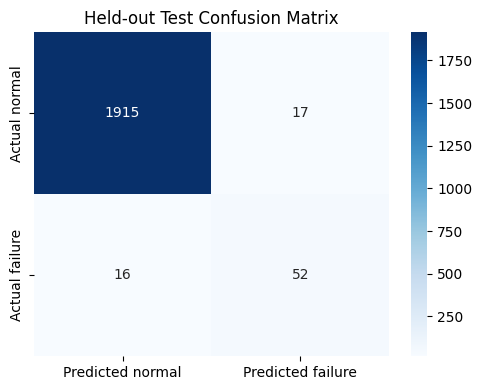

In [10]:
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= BEST_THRESHOLD).astype(int)

print("Selected model:", best_name)
print("Decision threshold:", BEST_THRESHOLD)
print("\nTest precision (failure):", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Test recall (failure):", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("Test F1 (failure):", round(f1_score(y_test, test_pred, zero_division=0), 4))
print("Test accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Test average precision:", round(average_precision_score(y_test, test_prob), 4))
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_prob), 4))

print("\nClassification report:")
print(classification_report(
    y_test, test_pred,
    target_names=["No failure", "Failure"],
    zero_division=0
))

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted normal", "Predicted failure"],
    yticklabels=["Actual normal", "Actual failure"]
)
plt.title("Held-out Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Retrain the selected model on train + validation data

After model/threshold selection and final evaluation, refit the selected model on all non-test rows so the exported model can use more labeled examples. Keep the test result as the final reported estimate. The saved threshold is included with the model.

In [11]:
X_trainval = pd.concat([X_train, X_val], axis=0)
y_trainval = pd.concat([y_train, y_val], axis=0)

final_model = candidates[best_name]
final_model.fit(X_trainval, y_trainval)

print("Final model retrained on", len(X_trainval), "rows.")

Final model retrained on 8000 rows.


## 12. Export the pickle artifact

The exported file contains the complete scikit-learn pipeline (preprocessing + classifier), the selected model name, feature list, threshold, and target name. This makes inference easier and helps avoid inconsistent preprocessing later.

In [12]:
import joblib
import json
from pathlib import Path
from datetime import datetime, timezone

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

artifact = {
    "model": final_model,
    "model_name": best_name,
    "threshold": BEST_THRESHOLD,
    "feature_columns": list(X.columns),
    "target": TARGET,
    "selection_metric": "validation average precision",
    "random_state": RANDOM_STATE,
    "dataset": "UCI AI4I 2020 Predictive Maintenance Dataset",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "test_metrics": {
        "precision_failure": float(precision_score(y_test, test_pred, zero_division=0)),
        "recall_failure": float(recall_score(y_test, test_pred, zero_division=0)),
        "f1_failure": float(f1_score(y_test, test_pred, zero_division=0)),
        "accuracy": float(accuracy_score(y_test, test_pred)),
        "average_precision": float(average_precision_score(y_test, test_prob)),
        "roc_auc": float(roc_auc_score(y_test, test_prob))
    }
}

pickle_path = ARTIFACT_DIR / "industrial_failure_model.pkl"
joblib_path = ARTIFACT_DIR / "industrial_failure_model.joblib"

joblib.dump(artifact, joblib_path)
# A .pkl extension is also supported by joblib's serialization format.
joblib.dump(artifact, pickle_path)

print("Saved:")
print(pickle_path.resolve())
print(joblib_path.resolve())
print("Model:", best_name)
print("Threshold:", BEST_THRESHOLD)

Saved:
/content/artifacts/industrial_failure_model.pkl
/content/artifacts/industrial_failure_model.joblib
Model: Hist Gradient Boosting
Threshold: 0.3


## 13. Download the exported model

### Google Colab
Run this cell to download the `.pkl` file to your computer.

In [13]:
# Google Colab only:
from google.colab import files
files.download("artifacts/industrial_failure_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Kaggle
In Kaggle, the saved file appears under the notebook's `/kaggle/working/artifacts/` output. Use **Save Version** and enable output saving to preserve/download it. If needed, create a zip:

In [ ]:
# Kaggle optional: create a zip containing both model artifacts.
import shutil
zip_path = shutil.make_archive(
    "/kaggle/working/industrial_failure_model_artifacts",
    "zip",
    root_dir="artifacts"
)
print("Created:", zip_path)

## 14. Test loading the pickle and making a prediction

The example uses the first held-out test row. Output is a probability from the classifier and an alert based on the selected threshold.

In [14]:
# Reload exactly as an API/backend would.
loaded_artifact = joblib.load("artifacts/industrial_failure_model.pkl")
loaded_model = loaded_artifact["model"]
threshold = loaded_artifact["threshold"]

sample = X_test.iloc[[0]].copy()
probability = float(loaded_model.predict_proba(sample)[0, 1])
predicted_class = int(probability >= threshold)

print("Input sensor values:")
display(sample)
print(f"Predicted failure probability: {probability:.1%}")
print("Predicted class:", "FAILURE RISK ALERT" if predicted_class == 1 else "Normal classification")
print("Threshold:", threshold)

Input sensor values:


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
2997,L,300.5,309.8,1345,62.7,153


Predicted failure probability: 7.2%
Predicted class: Normal classification
Threshold: 0.3


## 15. Download a metrics report

This creates a CSV file containing the validation comparison table for your project report.

In [15]:
comparison_path = "artifacts/model_comparison_validation.csv"
results_df.to_csv(comparison_path, index=False)
print("Saved:", comparison_path)

# Colab download (optional):
# from google.colab import files
# files.download(comparison_path)

Saved: artifacts/model_comparison_validation.csv


## Notes for your project report

- Describe this as **binary failure classification**, not RUL prediction.
- State that AI4I 2020 is a simulated dataset.
- Report test precision, recall, F1, average precision, ROC-AUC, and the confusion matrix.
- Explain the selected model using actual results from your run; do not claim Random Forest (or any model) is best before comparison.
- The threshold is selected on validation data, not the test set.
- The saved artifact uses `joblib` serialization with a `.pkl` extension. Load it only from a trusted source. When moving it to another environment, keep compatible versions of Python and scikit-learn.
- Do not use this model to automatically control real industrial machinery without domain validation, safety controls, and real machine data.

In [16]:

import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Load the exact model artifact exported by your notebook
artifact = joblib.load(
    "artifacts/industrial_failure_model.pkl"
)

model = artifact["model"]
threshold = artifact["threshold"]

# Predict the held-out test dataset
X_batch = X_test[artifact["feature_columns"]].copy()
actual = y_test.to_numpy()

probabilities = model.predict_proba(X_batch)[:, 1]
predictions = (probabilities >= threshold).astype(int)

print("Model:", artifact["model_name"])
print("Threshold:", threshold)
print("Number of test records:", len(X_batch))

print("\nAccuracy:", round(accuracy_score(actual, predictions), 4))
print("Failure precision:", round(
    precision_score(actual, predictions, zero_division=0), 4
))
print("Failure recall:", round(
    recall_score(actual, predictions, zero_division=0), 4
))
print("Failure F1-score:", round(
    f1_score(actual, predictions, zero_division=0), 4
))

print("\nConfusion matrix:")
print(confusion_matrix(actual, predictions))

print("\nClassification report:")
print(classification_report(
    actual, predictions,
    target_names=["Normal", "Failure"],
    zero_division=0
))


Model: Hist Gradient Boosting
Threshold: 0.3
Number of test records: 2000

Accuracy: 0.986
Failure precision: 0.7941
Failure recall: 0.7941
Failure F1-score: 0.7941

Confusion matrix:
[[1918   14]
 [  14   54]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1932
     Failure       0.79      0.79      0.79        68

    accuracy                           0.99      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.99      0.99      0.99      2000

